Using device: cpu
[CNN Baseline] Epoch 01/08 | Train Acc: 35.96% | Val Acc: 36.28%
[CNN Baseline] Epoch 02/08 | Train Acc: 43.26% | Val Acc: 43.89%
[CNN Baseline] Epoch 03/08 | Train Acc: 47.61% | Val Acc: 48.21%
[CNN Baseline] Epoch 04/08 | Train Acc: 50.69% | Val Acc: 50.76%
[CNN Baseline] Epoch 05/08 | Train Acc: 54.38% | Val Acc: 54.50%
[CNN Baseline] Epoch 06/08 | Train Acc: 54.81% | Val Acc: 55.30%
[CNN Baseline] Epoch 07/08 | Train Acc: 57.34% | Val Acc: 57.42%
[CNN Baseline] Epoch 08/08 | Train Acc: 58.21% | Val Acc: 58.02%
[CNN + Dropout(0.3)] Epoch 01/08 | Train Acc: 37.46% | Val Acc: 38.00%
[CNN + Dropout(0.3)] Epoch 02/08 | Train Acc: 41.97% | Val Acc: 42.26%
[CNN + Dropout(0.3)] Epoch 03/08 | Train Acc: 46.68% | Val Acc: 46.52%
[CNN + Dropout(0.3)] Epoch 04/08 | Train Acc: 50.53% | Val Acc: 50.57%
[CNN + Dropout(0.3)] Epoch 05/08 | Train Acc: 53.05% | Val Acc: 52.49%
[CNN + Dropout(0.3)] Epoch 06/08 | Train Acc: 55.77% | Val Acc: 55.93%
[CNN + Dropout(0.3)] Epoch 07/08 | T

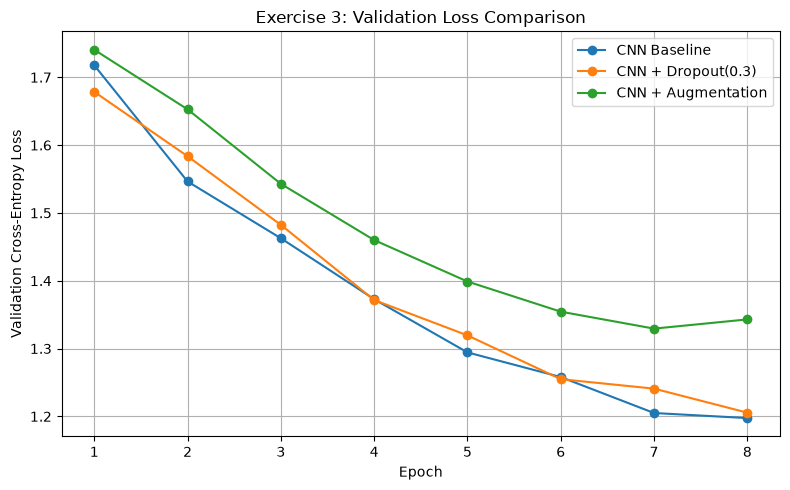

In [5]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["OMP_NUM_THREADS"] = "2"

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

norm_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)),
])

aug_transform = transforms.Compose([
    transforms.RandomRotation(10),
    transforms.RandomCrop(32, padding=2),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)),
])

raw_train_clean = datasets.CIFAR10(root="./data", train=True, download=True, transform=norm_transform)
raw_train_aug = datasets.CIFAR10(root="./data", train=True, download=True, transform=aug_transform)
test_dataset = datasets.CIFAR10(root="./data", train=False, download=True, transform=norm_transform)

indices = torch.randperm(len(raw_train_clean), generator=torch.Generator().manual_seed(42)).tolist()
train_idx, val_idx = indices[:40000], indices[40000:]

train_clean = Subset(raw_train_clean, train_idx)
train_aug = Subset(raw_train_aug, train_idx)
val_set = Subset(raw_train_clean, val_idx)

batch_size = 256
val_loader = DataLoader(val_set, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

def build_baseline_cnn():
  return nn.Sequential(
      nn.Conv2d(3, 32, kernel_size=3, padding=1),
      nn.ReLU(),
      nn.MaxPool2d(2, 2),
      nn.Conv2d(32, 64, kernel_size=3, padding=1),
      nn.ReLU(),
      nn.MaxPool2d(2, 2),
      nn.Conv2d(64, 128, kernel_size=3, padding=1),
      nn.ReLU(),
      nn.AdaptiveAvgPool2d((1, 1)),
      nn.Flatten(),
      nn.Linear(128, 10),
  )

def build_dropout_cnn():
  return nn.Sequential(
      nn.Conv2d(3, 32, kernel_size=3, padding=1),
      nn.ReLU(),
      nn.MaxPool2d(2, 2),
      nn.Conv2d(32, 64, kernel_size=3, padding=1),
      nn.ReLU(),
      nn.MaxPool2d(2, 2),
      nn.Conv2d(64, 128, kernel_size=3, padding=1),
      nn.ReLU(),
      nn.AdaptiveAvgPool2d((1, 1)),
      nn.Flatten(),
      nn.Dropout(p=0.3),
      nn.Linear(128, 10),
  )

def eval_loader(model, loader, criterion):
  model.eval()
  loss_sum, ok, n = 0.0, 0, 0
  with torch.no_grad():
    for x, y in loader:
      x, y = x.to(device), y.to(device)
      out = model(x)
      loss_sum += float(criterion(out, y).item()) * x.size(0)
      ok += int((out.argmax(1) == y).sum().item())
      n += int(y.size(0))
  return loss_sum / n, 100.0 * ok / n

def run_experiment(name, model, train_ds, epochs=8):
  torch.manual_seed(42)
  model = model.to(device)
  tr_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
  criterion = nn.CrossEntropyLoss()
  optimizer = optim.Adam(model.parameters(), lr=1e-3)

  va_losses = []
  for ep in range(1, epochs + 1):
    model.train()
    for x, y in tr_loader:
      x, y = x.to(device), y.to(device)
      optimizer.zero_grad()
      loss = criterion(model(x), y)
      loss.backward()
      optimizer.step()
    _, tr_a = eval_loader(model, tr_loader, criterion)
    va_l, va_a = eval_loader(model, val_loader, criterion)
    va_losses.append(va_l)
    print(f"[{name}] Epoch {ep:02d}/{epochs:02d} | Train Acc: {tr_a:.2f}% | Val Acc: {va_a:.2f}%")

  _, final_tr_acc = eval_loader(model, tr_loader, criterion)
  _, final_va_acc = eval_loader(model, val_loader, criterion)
  _, final_te_acc = eval_loader(model, test_loader, criterion)
  return {
      "name": name,
      "train_acc": final_tr_acc,
      "val_acc": final_va_acc,
      "test_acc": final_te_acc,
      "gap": final_tr_acc - final_te_acc,
      "va_losses": va_losses,
  }

epochs = 8
results = [
    run_experiment("CNN Baseline", build_baseline_cnn(), train_clean, epochs=epochs),
    run_experiment("CNN + Dropout(0.3)", build_dropout_cnn(), train_clean, epochs=epochs),
    run_experiment("CNN + Augmentation", build_baseline_cnn(), train_aug, epochs=epochs),
]

print("\n--- Summary ---")
for r in results:
  print(
      f"{r['name']:22s} | Train: {r['train_acc']:6.2f}% | Val:"
      f" {r['val_acc']:6.2f}% | Test: {r['test_acc']:6.2f}% | Gap:"
      f" {r['gap']:+6.2f}%"
  )

plt.figure(figsize=(8, 5))
for r in results:
  plt.plot(range(1, epochs + 1), r["va_losses"], marker="o", label=r["name"])
plt.title("Exercise 3: Validation Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Validation Cross-Entropy Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("exercise3_val_loss.png", dpi=150)
plt.show()